> Known issue in this notebook: Cells must be executed in order, cells are not self-sustained

In [1]:
import os
import h3
from glob import glob
from matplotlib import pyplot as plt
import pandas as pd
import geopandas as gpd
import contextily as cx
import seaborn as sns
from shapely.geometry import Polygon
from shapely.geometry.linestring import LineString
from shapely.geometry.point import Point
import ast

In [2]:
DATAPATH = '../../data/'
HEX_RES = 8
DEMAND_PATH = f'demand/weekday_time_bucket_4h_h3_start_{HEX_RES}.csv'
CORRIDOR_PATH = 'environment/'

plt.rcParams.update({'axes.titlesize': 'xx-large'})

# Demand Heatmap

In [94]:
# Timebucket 4: 12:00 - 16:00
# Timebucket 5: 16:00 - 20:00
# Timebucket 6: 20:00 - 24:00

demand = pd.read_csv(os.path.join(DATAPATH, DEMAND_PATH))
demand = demand[(demand['time_bucket_4h'] == 4) & (~demand['is_holiday'])]
demand = demand.join(demand.groupby(f'h3_end_{HEX_RES}')['total_trips'].sum(), on=f'h3_end_{HEX_RES}', rsuffix='_end')
demand.rename(columns={'sum_total_trips': 'total_trips_start'}, inplace=True)
demand[f'h3_start_{HEX_RES}_poly'] = demand.apply(lambda x: Polygon(h3.h3_to_geo_boundary(x[f'h3_start_{HEX_RES}'], geo_json=True)), axis=1)
demand[f'h3_end_{HEX_RES}_poly'] = demand.apply(lambda x: Polygon(h3.h3_to_geo_boundary(x[f'h3_end_{HEX_RES}'], geo_json=True)), axis=1)

In [95]:
demand_start = gpd.GeoDataFrame(demand[[f'h3_start_{HEX_RES}', f'h3_end_{HEX_RES}', 'total_trips_start']], geometry=demand[f'h3_start_{HEX_RES}_poly'], crs='EPSG:4326')
demand_start_wm = demand_start.to_crs(epsg=3857)

demand_end = gpd.GeoDataFrame(demand[[f'h3_start_{HEX_RES}', f'h3_end_{HEX_RES}', 'total_trips_end']], geometry=demand[f'h3_end_{HEX_RES}_poly'], crs='EPSG:4326')
demand_end_wm = demand_end.to_crs(epsg=3857)

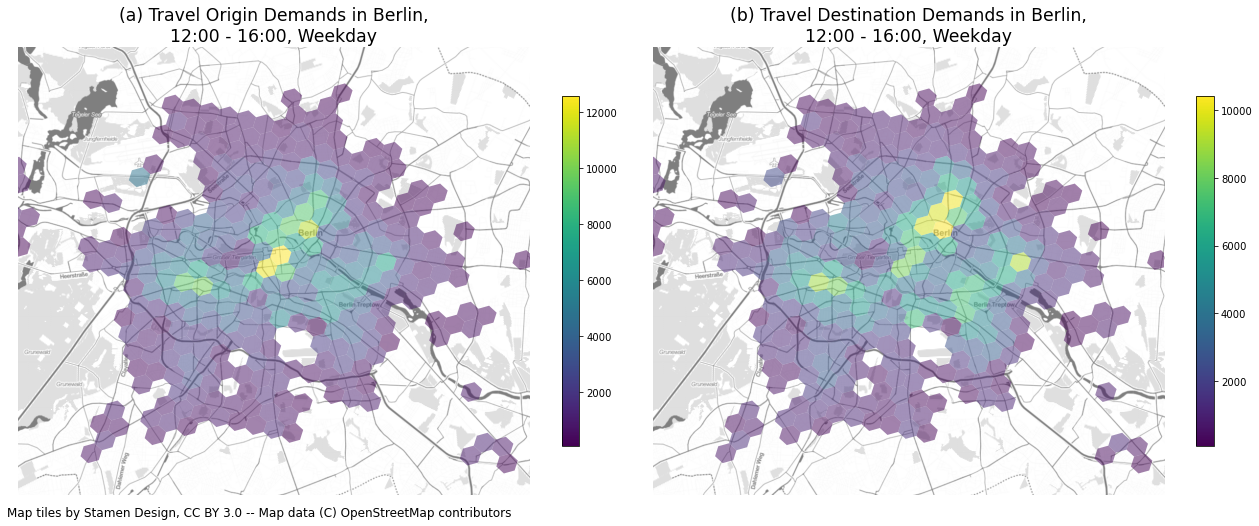

In [96]:
fig, ax = plt.subplots(figsize=(18,10), ncols=2)

demand_start_wm[~demand_start_wm.duplicated(subset=[f'h3_start_{HEX_RES}'])].plot(
    ax=ax[0], column='total_trips_start', alpha=0.5, legend=True, legend_kwds={'shrink': 0.5})
cx.add_basemap(ax[0], source=cx.providers.Stamen.Toner, alpha=.5, attribution='')
ax[0].set_title('(a) Travel Origin Demands in Berlin,\n12:00 - 16:00, Weekday')
ax[0].set_xlim(1.47*1e6,1.51*1e6)
ax[0].set_ylim(6.875*1e6, 6.91*1e6)
ax[0].axis('off')

demand_end_wm[~demand_end_wm.duplicated(subset=[f'h3_end_{HEX_RES}'])].plot(
    ax=ax[1], column='total_trips_end', alpha=0.5, legend=True, legend_kwds={'shrink': 0.5})
cx.add_basemap(ax[1], source=cx.providers.Stamen.Toner, alpha=.5, attribution='')
ax[1].set_title('(b) Travel Destination Demands in Berlin,\n12:00 - 16:00, Weekday')
ax[1].set_xlim(1.47*1e6,1.51*1e6)
ax[1].set_ylim(6.875*1e6, 6.91*1e6)
ax[1].axis('off')

fig.text(x=0, y=0.16, s=cx.providers.Stamen.Toner.attribution, fontsize='large')
plt.tight_layout()
plt.savefig(os.path.join(DATAPATH, f'output/figures/demands_1620_weekday_hex{HEX_RES}.png'), bbox_inches='tight')
plt.show()

# Corridor construction

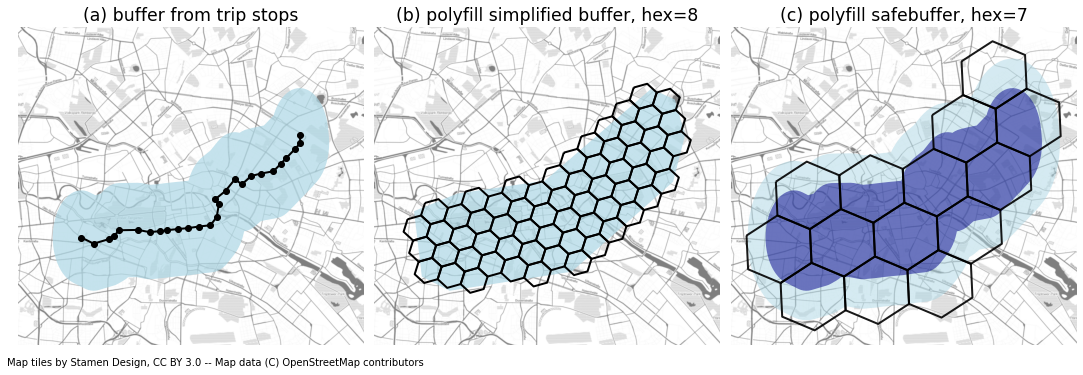

In [20]:
DATAPATH = '/home/jmuires/source/urban-mobility-simulation/data/infrastructure'
TRANSIT_OUT = os.path.join(DATAPATH, 'transit_timetable.csv')

timetable = pd.read_csv(TRANSIT_OUT)

# now that we have the route, we need to build two things:
# 1. a demand modifier buffer around it to tune up demand generation around the route for dynamic transit
# 2. an action space that is also a buffer around it, but in higher resolution
# These two should be as similar as possible.

BUFFERSIZE = 0.016
# play around with this until the red area in the plot looks sufficiently polyfilled with green hexagon cells
# the same polyfill will happen in the simulation demand factory
SAFEBUFFER = 0.01
SIMPLIFY_RATIO = 0.005

# TRIP = 163296946 this will be in two timebuckets when time multiplier for dynamic route is used
# TRIP = 163297125 # direction 0
TRIP = 163296942 # direction 1

import h3
import json
from matplotlib import pyplot as plt
from shapely.geometry.point import Point
from shapely.geometry.polygon import Polygon
from shapely.geometry.linestring import LineString

route_stops = timetable[timetable['trip_id'] == TRIP]
route_stops = route_stops[~route_stops.duplicated(subset=['stop_lat', 'stop_lon'])]
route_stops = route_stops[~route_stops.duplicated(subset=['stop_sequence'])]
stops_points = route_stops.sort_values('stop_sequence').apply(lambda x: Point(x['stop_lon'], x['stop_lat']), axis=1)
stops_gpd = gpd.GeoDataFrame.from_records([{'id': k, 'geometry': v} for k, v in enumerate(stops_points)])
# stops_gpd.to_json(drop_id=True)

stops_line = gpd.GeoSeries(LineString(list(stops_points)))
buffer = LineString(list(stops_points)).buffer(BUFFERSIZE)
buffer_gpd = gpd.GeoSeries(buffer)
safebuffer = gpd.GeoSeries(buffer.buffer(SAFEBUFFER))
simplified_buffer = gpd.GeoSeries(buffer).simplify(SIMPLIFY_RATIO)

fig, ax = plt.subplots(1, 3, figsize=(15,5), gridspec_kw={'height_ratios': [1], 'width_ratios': [1,1,1]})

# a)
stops_line.crs = 'EPSG:4326'
stops_line_wm = stops_line.to_crs(epsg=3857)
stops_line_wm.plot(ax=ax[0], color='black', alpha=1, linewidth=2)
buffer_gpd.crs = 'EPSG:4326'
buffer_wm = buffer_gpd.to_crs(epsg=3857)
buffer_wm.plot(ax=ax[0], color='lightblue', alpha=.7)
stops_gpd.crs = 'EPSG:4326'
stops_gpd_wm = stops_gpd.to_crs(epsg=3857)
stops_gpd_wm.plot(ax=ax[0], color='black')

# b)
simplified_buffer.crs = 'EPSG:4326'
simplified_buffer_wm = simplified_buffer.to_crs(epsg=3857)
simplified_buffer_wm.plot(ax=ax[1], color='lightblue', alpha=.7)
# stops_line_wm.plot(ax=ax[1], color='red', alpha=1, linewidth=2)
# stops_gpd_wm.plot(ax=ax[1], color='black', alpha=1, markersize=2)
# Action Space Hex Resolution 8
hexs_8 = h3.polyfill(json.loads(simplified_buffer.to_json())['features'][0]['geometry'], res=8, geo_json_conformant=True)
hexs_8_gpd = gpd.GeoDataFrame.from_records([{'hex': h, 'geometry': Polygon(h3.h3_to_geo_boundary(h, geo_json=True))} for h in hexs_8])
hexs_8_gpd.crs = 'EPSG:4326'
hexs_8_gpd_wm = hexs_8_gpd.to_crs(epsg=3857)
hexs_8_gpd_wm.plot(ax = ax[1], alpha=1, facecolor="none", edgecolor='black', linewidth=2)

# c)
safebuffer.crs = 'EPSG:4326'
safebuffer_wm = safebuffer.to_crs(epsg=3857)
safebuffer_wm.plot(ax=ax[2], color='lightblue', alpha=.5)
buffer_wm.plot(ax=ax[2], color='darkblue', alpha=.5)
# Demand Generation buffer Hex Resolution 7
hexs_7 = h3.polyfill(json.loads(safebuffer.to_json())['features'][0]['geometry'], res=7, geo_json_conformant=True)
hexs_7_gpd = gpd.GeoDataFrame.from_records([{'hex': h, 'geometry': Polygon(h3.h3_to_geo_boundary(h, geo_json=True))} for h in hexs_7])
hexs_7_gpd.crs = 'EPSG:4326'
hexs_7_gpd_wm = hexs_7_gpd.to_crs(epsg=3857)
hexs_7_gpd_wm.plot(ax = ax[2], alpha=.9, facecolor="none", edgecolor='black', linewidth=2)


ax[0].set_ylim(ax[2].get_ylim())
ax[1].set_ylim(ax[2].get_ylim())
ax[0].set_xlim(ax[2].get_xlim())
ax[1].set_xlim(ax[2].get_xlim())

# add background map
for a in ax:
    cx.add_basemap(a, source=cx.providers.Stamen.Toner, alpha=.5, attribution='')
    a.set_aspect('equal')
    a.axis('off')

ax[0].set_title('(a) buffer from trip stops')
ax[1].set_title('(b) polyfill simplified buffer, hex=8')
ax[2].set_title('(c) polyfill safebuffer, hex=7')

fig.text(x=0, y=0, s=cx.providers.Stamen.Toner.attribution)

plt.tight_layout()
plt.savefig(os.path.join(DATAPATH, '../output/figures/corridor_construction.png'), bbox_inches='tight')
plt.show()

# Action corridor and movement

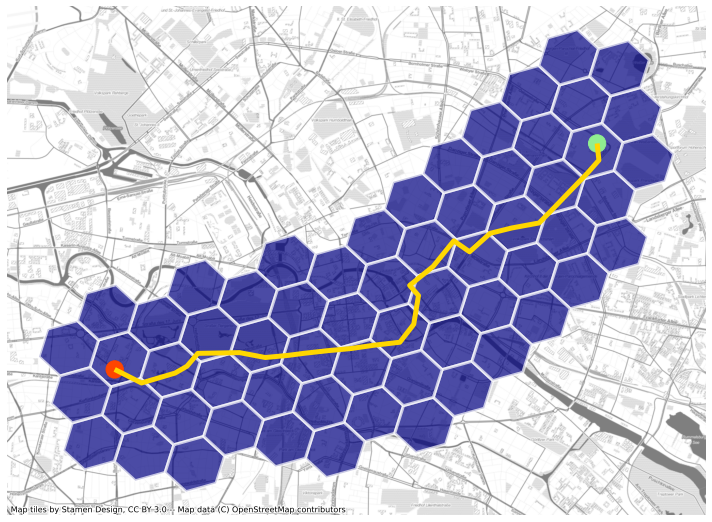

In [21]:
fig, ax = plt.subplots(figsize=(10,10))

stops_gpd_wm['color'] = 'none'
stops_gpd_wm['markersize'] = 0
stops_gpd_wm.loc[0,'color'] = 'lightgreen'
stops_gpd_wm.loc[0, 'markersize'] = 300
stops_gpd_wm.loc[26,'color'] = 'orangered'
stops_gpd_wm.loc[26, 'markersize'] = 300

stops_line_wm.plot(ax=ax, color='gold', linewidth=5)
hexs_8_gpd_wm.plot(ax = ax, alpha=.7, facecolor="navy", edgecolor='white', linewidth=3)
stops_gpd_wm.plot(ax=ax, c=stops_gpd_wm['color'], markersize=stops_gpd_wm['markersize'], alpha=1, marker='o')
cx.add_basemap(ax, source=cx.providers.Stamen.Toner, alpha=.5)
# ax.set_aspect('equal')
ax.axis('off')


plt.tight_layout()
plt.savefig(os.path.join(DATAPATH, '../output/figures/action_corridor.png'), bbox_inches='tight')
plt.show()

# Movement

### using hexagons

In [47]:
TRACKING_PATH = 'output/tracking'
TRACKINGS = [
    "5000_episodes_action_space=['STAY', 'UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_movements_20211219-170957-111506.csv",
    "5000_episodes_action_space=['STAY', 'UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_movements_20211219-170957-342609.csv",
    "5000_episodes_action_space=['STAY', 'UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_movements_20211219-170957-396001.csv",
    "5000_episodes_action_space=['STAY', 'UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_movements_20211219-170957-407863.csv",
    "5000_episodes_action_space=['STAY', 'UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_movements_20211219-170957-516659.csv",
    "5000_episodes_action_space=['STAY', 'UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_movements_20211219-170957-524220.csv",
    "5000_episodes_action_space=['STAY', 'UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_movements_20211219-170957-621583.csv",
    "5000_episodes_action_space=['STAY', 'UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_movements_20211219-170957-692911.csv",
    "5000_episodes_action_space=['STAY', 'UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_movements_20211219-170957-911638.csv",
    "5000_episodes_action_space=['STAY', 'UP', 'DOWN', 'UP_LEFT', 'UP_RIGHT', 'DOWN_LEFT', 'DOWN_RIGHT']_movements_20211219-170957-928028.csv",
]
DATAPATH = '../../data/'

BINS = [(0,50), (500,550), (4950,5000)]
# BINS = [(0,30), (30,60), (70,100)]

In [48]:
# multiple files
tracks = []

for t in TRACKINGS:
    tracks.append(pd.read_csv(os.path.join(DATAPATH, TRACKING_PATH, t)))
    
tracks = pd.concat(tracks, axis=0)

In [49]:
# TODO: use h3 vect for geo_to_h3

# position coordinates tuple needs to be reversed by using [::-1]
tracks['hex'] = tracks.apply(lambda x: h3.geo_to_h3(*ast.literal_eval(x['position'])[::-1], resolution=HEX_RES), axis=1)
# tracks = tracks.groupby(['episode', 'hex']).count()['move_start'].reset_index().rename(columns={'move_start': 'visited'})
tracks['hex_geo'] = tracks.apply(lambda x: Polygon(h3.h3_to_geo_boundary(x['hex'], geo_json=True)), axis=1)
# tracks = gpd.GeoDataFrame(tracks[['episode', 'visited']], geometry=tracks['hex_geo'], crs='EPSG:4326')
tracks = gpd.GeoDataFrame(tracks[['episode']], geometry=tracks['hex_geo'], crs='EPSG:4326')

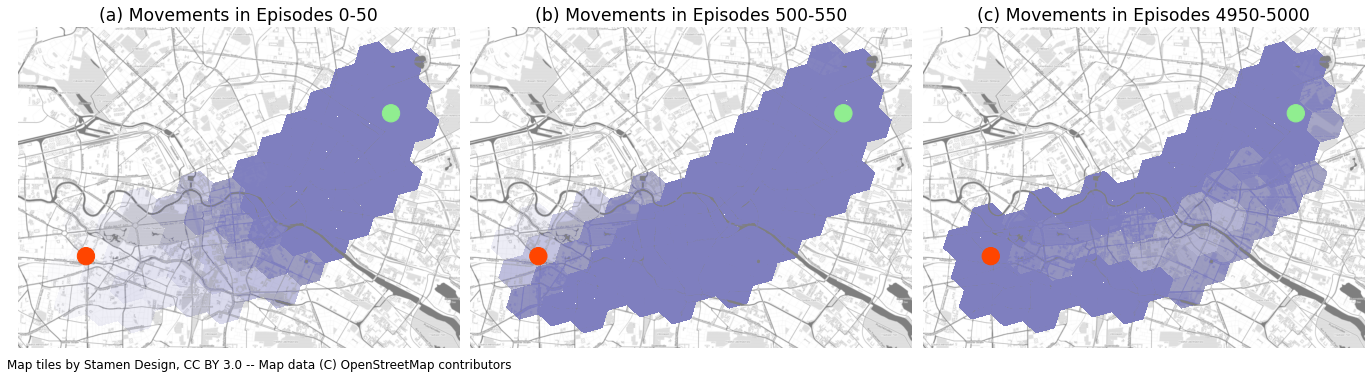

In [50]:
fig, ax = plt.subplots(1,3,figsize=(19,6))
tracks_wm = tracks.to_crs(epsg=3857) # web mercator

for (i, b), x in zip(enumerate(BINS), ['(a)', '(b)', '(c)']):
    # n_tracks = len(tracks_wm[(tracks_wm['episode']>=b[0]) & (tracks_wm['episode']<=b[1])])
    tracks_wm[(tracks_wm['episode']>=b[0]) & (tracks_wm['episode']<=b[1])].plot(ax=ax[i], alpha=0.005, color='navy')
    # tracks_lines_wm[(tracks_lines_wm['episode']>=b[0]) & (tracks_lines_wm['episode']<=b[1])].plot(
    #     ax=ax[i], alpha=.5, linewidth=2, color='navy')
    stops_gpd_wm.plot(ax=ax[i], c=stops_gpd_wm['color'], markersize=stops_gpd_wm['markersize'], alpha=1, marker='o')
    cx.add_basemap(ax[i], source=cx.providers.Stamen.Toner, alpha=.5, attribution='')
    ax[i].set_title(f'{x} Movements in Episodes {b[0]}-{b[1]}')
    # ax[i].set_aspect('equal')
    ax[i].axis('off')

x_extents = ax[2].get_xlim()
y_extents = ax[2].get_ylim()

for a in ax[:-1]:
    a.set_xlim(x_extents)
    a.set_ylim(y_extents)

plt.tight_layout()
fig.text(x=0, y=0.08, s=cx.providers.Stamen.Toner.attribution, fontsize='large')
# fig.suptitle('STAY in action set')
plt.savefig(os.path.join(DATAPATH, 'output/figures/learning_movements_stay.png'), bbox_inches='tight')
plt.show()

### using lines for benchmark runs

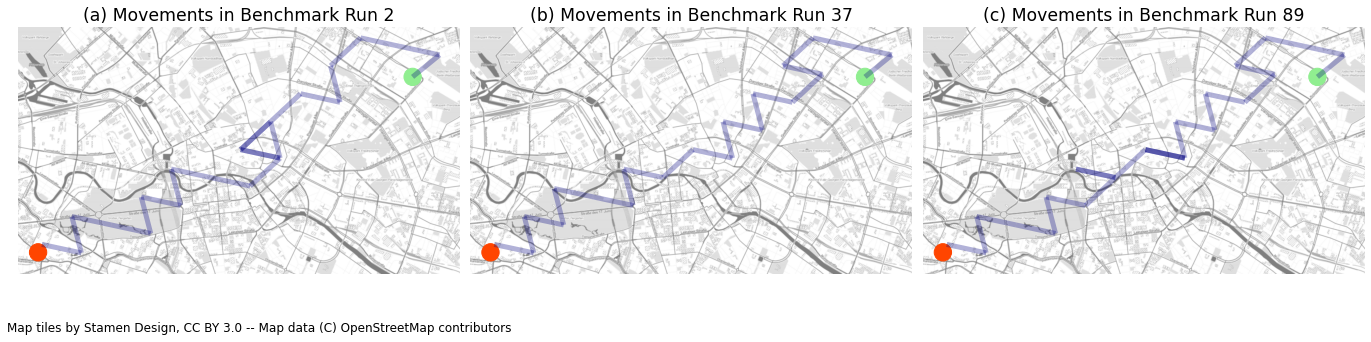

In [57]:
DATAPATH = '../../data/'
TRACKING_PATH = 'output/tracking/'
TRACKING = '100_benchmark_agent_movements_20211220-203729.csv'

# BINS = [(0,100), (500,600), (4900,5000)]
EPISODES = [2, 37, 89]

tracks_lines = pd.read_csv(os.path.join(DATAPATH, TRACKING_PATH, TRACKING))
tracks_lines['move'] = tracks_lines.apply(lambda x: LineString((Point(ast.literal_eval(x['move_start'])), Point(ast.literal_eval(x['move_end'])))), axis=1)
tracks_lines = gpd.GeoDataFrame(tracks_lines[['episode']], geometry=tracks_lines['move'], crs='EPSG:4326')

fig, ax = plt.subplots(1,3,figsize=(19,6))

tracks_lines_wm = tracks_lines.to_crs(epsg=3857) # web mercator

for (i, e), x in zip(enumerate(EPISODES), ['(a)', '(b)', '(c)']):
    tracks_lines_wm[tracks_lines_wm['episode']==e].plot(ax=ax[i], alpha=.3, linewidth=5, color='navy')
    stops_gpd_wm.plot(ax=ax[i], c=stops_gpd_wm['color'], markersize=stops_gpd_wm['markersize'], alpha=1, marker='o')
    cx.add_basemap(ax[i], source=cx.providers.Stamen.Toner, alpha=.5, attribution='')
    ax[i].set_title(f'{x} Movements in Benchmark Run {e}')
    # ax[i].set_aspect('equal')
    ax[i].axis('off')

x_extents = ax[2].get_xlim()
y_extents = ax[2].get_ylim()

for a in ax[:-1]:
    a.set_xlim(x_extents)
    a.set_ylim(y_extents)

plt.tight_layout()
fig.text(x=0, y=0.08, s=cx.providers.Stamen.Toner.attribution, fontsize='large')
plt.savefig(os.path.join(DATAPATH, 'output/figures/agent_movements.png'), bbox_inches='tight')
plt.show()